In [1]:
import torch
import torchvision
import torchvision.transforms as transforms
from torch.utils.data import DataLoader

In [2]:
BATCH_SIZE = 128

In [3]:
hyperparameters = {
    'hidden_activation': 'ReLU',
    'num_hidden_layers': 2,
    'neurons_per_hidden_layer': 128,
    'dropout_rate': 0.25,
    'weight_decay': 0.0001,
    'num_epochs': 20
}

print("Defined Hyperparameters:")
print(hyperparameters)

Defined Hyperparameters:
{'hidden_activation': 'ReLU', 'num_hidden_layers': 2, 'neurons_per_hidden_layer': 128, 'dropout_rate': 0.25, 'weight_decay': 0.0001, 'num_epochs': 20}


In [4]:
# Define a transform to normalize the data
transform = transforms.Compose(
    [transforms.ToTensor(),
     transforms.Normalize((0.5, 0.5, 0.5), (0.5, 0.5, 0.5))])

# Load the training dataset
trainset = torchvision.datasets.CIFAR10(root='./data', train=True,
                                        download=True, transform=transform)

# Create a DataLoader for the training set
trainloader = DataLoader(trainset, batch_size=BATCH_SIZE,
                                          shuffle=True, num_workers=2)

# Load the testing dataset
testset = torchvision.datasets.CIFAR10(root='./data', train=False,
                                       download=True, transform=transform)

# Create a DataLoader for the testing set
testloader = DataLoader(testset, batch_size=4,
                                         shuffle=False, num_workers=2)

classes = ('plane', 'car', 'bird', 'cat',
           'deer', 'dog', 'frog', 'horse', 'ship', 'truck')

Files already downloaded and verified
Files already downloaded and verified


In [5]:
print("CIFAR-10 training and testing datasets loaded successfully!")
print(f"Number of training samples: {len(trainset)}")
print(f"Number of test samples: {len(testset)}")

CIFAR-10 training and testing datasets loaded successfully!
Number of training samples: 50000
Number of test samples: 10000


In [6]:
import torch.nn as nn

# Define the MLP model class
class MLP(nn.Module):
    def __init__(self, hyperparameters):
        super(MLP, self).__init__()

        # Determine input size for CIFAR-10 images (3 channels * 32 width * 32 height)
        input_size = 3 * 32 * 32
        num_classes = 10 # CIFAR-10 has 10 classes

        # Access hyperparameters
        hidden_activation_str = hyperparameters['hidden_activation']
        num_hidden_layers = hyperparameters['num_hidden_layers']
        neurons_per_hidden_layer = hyperparameters['neurons_per_hidden_layer']
        dropout_rate = hyperparameters['dropout_rate']

        layers = []

        # Map hidden_activation string to PyTorch activation module
        if hidden_activation_str == 'ReLU':
            activation_fn = nn.ReLU()
        elif hidden_activation_str == 'Tanh':
            activation_fn = nn.Tanh()
        elif hidden_activation_str == 'Sigmoid':
            activation_fn = nn.Sigmoid()
        else:
            raise ValueError(f"Unsupported activation function: {hidden_activation_str}")

        current_in_features = input_size

        # Construct hidden layers
        if num_hidden_layers > 0:
            # First hidden layer
            layers.append(nn.Linear(current_in_features, neurons_per_hidden_layer))
            layers.append(activation_fn)
            if dropout_rate > 0:
                layers.append(nn.Dropout(dropout_rate))
            current_in_features = neurons_per_hidden_layer # Update input features for next layer

            # Subsequent hidden layers (if any, num_hidden_layers - 1 remaining)
            for _ in range(num_hidden_layers - 1):
                layers.append(nn.Linear(current_in_features, neurons_per_hidden_layer))
                layers.append(activation_fn)
                if dropout_rate > 0:
                    layers.append(nn.Dropout(dropout_rate))
                # current_in_features remains neurons_per_hidden_layer for these intermediate layers

        # Output layer
        # If num_hidden_layers was 0, current_in_features is input_size. Otherwise, it's neurons_per_hidden_layer.
        layers.append(nn.Linear(current_in_features, num_classes))

        self.layers = nn.Sequential(*layers)

    def forward(self, x):
        # Flatten the input tensor from (batch_size, channels, height, width) to (batch_size, -1)
        x = x.view(x.size(0), -1)
        return self.layers(x)

# Device configuration
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Using device: {device}")

# Instantiate an object of the MLP class using the defined hyperparameters
model = MLP(hyperparameters).to(device)

# Print the model architecture to verify its structure
print("\nMLP Model Architecture:")
print(model)


Using device: cuda

MLP Model Architecture:
MLP(
  (layers): Sequential(
    (0): Linear(in_features=3072, out_features=128, bias=True)
    (1): ReLU()
    (2): Dropout(p=0.25, inplace=False)
    (3): Linear(in_features=128, out_features=128, bias=True)
    (4): ReLU()
    (5): Dropout(p=0.25, inplace=False)
    (6): Linear(in_features=128, out_features=10, bias=True)
  )
)


In [7]:
import torch.optim as optim

# Define the loss function
criterion = nn.CrossEntropyLoss()

# Define the optimizer with weight decay
optimizer = optim.Adam(model.parameters(), lr=0.001, weight_decay=hyperparameters['weight_decay'])

print("Loss function and optimizer defined successfully!")

Loss function and optimizer defined successfully!


In [8]:
import numpy as np

# Initialize lists to store metrics
train_losses = []
train_accuracies = []
val_losses = []
val_accuracies = []

# Get number of epochs from hyperparameters
num_epochs = hyperparameters['num_epochs']

print("Starting model training...")

for epoch in range(num_epochs):
    # Training phase
    model.train()  # Set model to training mode
    running_train_loss = 0.0
    correct_train = 0
    total_train = 0

    for i, data in enumerate(trainloader, 0):
        inputs, labels = data
        inputs, labels = inputs.to(device), labels.to(device)

        # Zero the parameter gradients
        optimizer.zero_grad()

        # Forward pass
        outputs = model(inputs)
        loss = criterion(outputs, labels)

        # Backward pass and optimize
        loss.backward()
        optimizer.step()

        running_train_loss += loss.item()
        _, predicted = torch.max(outputs.data, 1)
        total_train += labels.size(0)
        correct_train += (predicted == labels).sum().item()

    avg_train_loss = running_train_loss / len(trainloader)
    train_accuracy = 100 * correct_train / total_train
    train_losses.append(avg_train_loss)
    train_accuracies.append(train_accuracy)

    # Validation phase
    model.eval()  # Set model to evaluation mode
    running_val_loss = 0.0
    correct_val = 0
    total_val = 0
    with torch.no_grad():  # Disable gradient calculation for validation
        for data in testloader:
            inputs, labels = data
            inputs, labels = inputs.to(device), labels.to(device)

            outputs = model(inputs)
            loss = criterion(outputs, labels)

            running_val_loss += loss.item()
            _, predicted = torch.max(outputs.data, 1)
            total_val += labels.size(0)
            correct_val += (predicted == labels).sum().item()

    avg_val_loss = running_val_loss / len(testloader)
    val_accuracy = 100 * correct_val / total_val
    val_losses.append(avg_val_loss)
    val_accuracies.append(val_accuracy)

    print(f'Epoch {epoch + 1}/{num_epochs}: ')
    print(f'  Train Loss: {avg_train_loss:.4f}, Train Accuracy: {train_accuracy:.2f}%')
    print(f'  Val Loss: {avg_val_loss:.4f}, Val Accuracy: {val_accuracy:.2f}%')

print("Finished Training!")

Starting model training...
Epoch 1/20: 
  Train Loss: 1.7729, Train Accuracy: 36.90%
  Val Loss: 1.5794, Val Accuracy: 44.00%
Epoch 2/20: 
  Train Loss: 1.6080, Train Accuracy: 43.18%
  Val Loss: 1.4876, Val Accuracy: 46.98%
Epoch 3/20: 
  Train Loss: 1.5418, Train Accuracy: 45.24%
  Val Loss: 1.4490, Val Accuracy: 49.44%
Epoch 4/20: 
  Train Loss: 1.5007, Train Accuracy: 47.12%
  Val Loss: 1.4175, Val Accuracy: 50.39%
Epoch 5/20: 
  Train Loss: 1.4658, Train Accuracy: 48.37%
  Val Loss: 1.4043, Val Accuracy: 50.64%
Epoch 6/20: 
  Train Loss: 1.4350, Train Accuracy: 49.12%
  Val Loss: 1.3789, Val Accuracy: 51.48%
Epoch 7/20: 
  Train Loss: 1.4097, Train Accuracy: 50.08%
  Val Loss: 1.3561, Val Accuracy: 52.59%
Epoch 8/20: 
  Train Loss: 1.3877, Train Accuracy: 50.90%
  Val Loss: 1.3620, Val Accuracy: 51.87%
Epoch 9/20: 
  Train Loss: 1.3723, Train Accuracy: 51.18%
  Val Loss: 1.3569, Val Accuracy: 52.53%
Epoch 10/20: 
  Train Loss: 1.3500, Train Accuracy: 52.02%
  Val Loss: 1.3539, Val

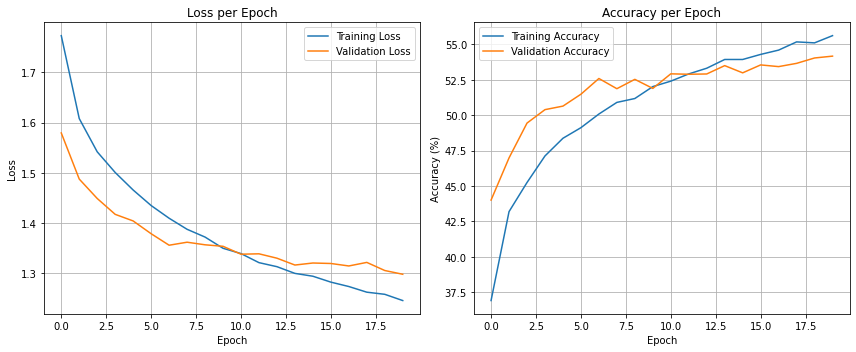

Loss and Accuracy curves visualized successfully!


In [9]:
import matplotlib.pyplot as plt

# Create plots for loss and accuracy
plt.figure(figsize=(12, 5))

# Plot training and validation loss
plt.subplot(1, 2, 1) # 1 row, 2 columns, first plot
plt.plot(train_losses, label='Training Loss')
plt.plot(val_losses, label='Validation Loss')
plt.title('Loss per Epoch')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)

# Plot training and validation accuracy
plt.subplot(1, 2, 2) # 1 row, 2 columns, second plot
plt.plot(train_accuracies, label='Training Accuracy')
plt.plot(val_accuracies, label='Validation Accuracy')
plt.title('Accuracy per Epoch')
plt.xlabel('Epoch')
plt.ylabel('Accuracy (%)')
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

print("Loss and Accuracy curves visualized successfully!")

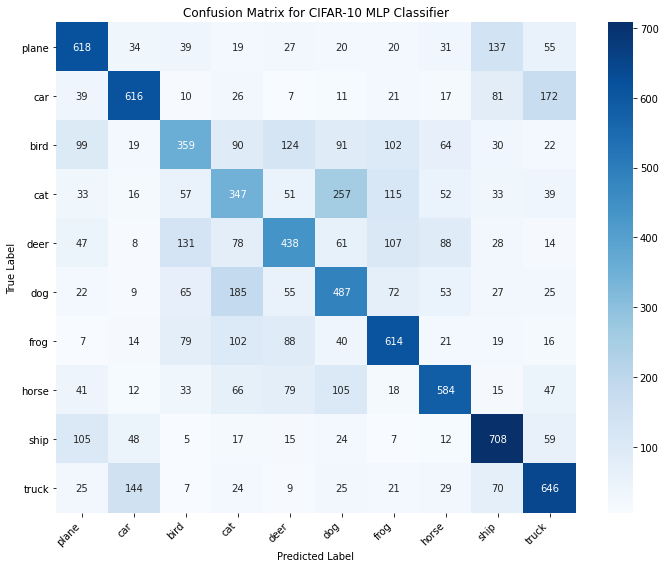

Confusion matrix visualized successfully.


In [11]:
import matplotlib.pyplot as plt
import seaborn as sns


from sklearn.metrics import confusion_matrix
import numpy as np

all_labels = []
all_predicted = []

model.eval() # Set model to evaluation mode
with torch.no_grad():
    for data in testloader:
        images, labels = data
        images, labels = images.to(device), labels.to(device)
        outputs = model(images)
        _, predicted = torch.max(outputs.data, 1)
        
        all_labels.extend(labels.cpu().numpy())
        all_predicted.extend(predicted.cpu().numpy())

# Compute the confusion matrix
cm = confusion_matrix(all_labels, all_predicted)



# Create a figure and an axes object
plt.figure(figsize=(10, 8))

# Use seaborn's heatmap for a more visually appealing confusion matrix
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=True,
            xticklabels=classes, yticklabels=classes)

plt.title('Confusion Matrix for CIFAR-10 MLP Classifier')
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.xticks(rotation=45, ha='right') # Rotate x-axis labels for better readability
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

print("Confusion matrix visualized successfully.")